# XGBoost

## 1. Setup & Quick Data Exploration

We start by importing our core data, visualization, modeling, and evaluation libraries. We will use the classic **Iris dataset** (`load_iris`) because it trains in milliseconds during a live session while still giving us a clean **multi-class classification** problem (3 flower species, 4 numerical features).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV

from xgboost import XGBClassifier, plot_tree

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

sns.set_theme(style="whitegrid", palette="deep")

In [2]:
# Load dataset as a pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print(f"Dataset shape: {df.shape}")
print("\nClass counts:")
print(df["species"].value_counts())

df.head()

Dataset shape: (150, 6)

Class counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Let's check summary statistics and a quick pairplot. Look at how **petal length** and **petal width** separate *setosa* cleanly, while *versicolor* and *virginica* have some overlap—this is where decision tree splits will do the heavy lifting.

In [3]:
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


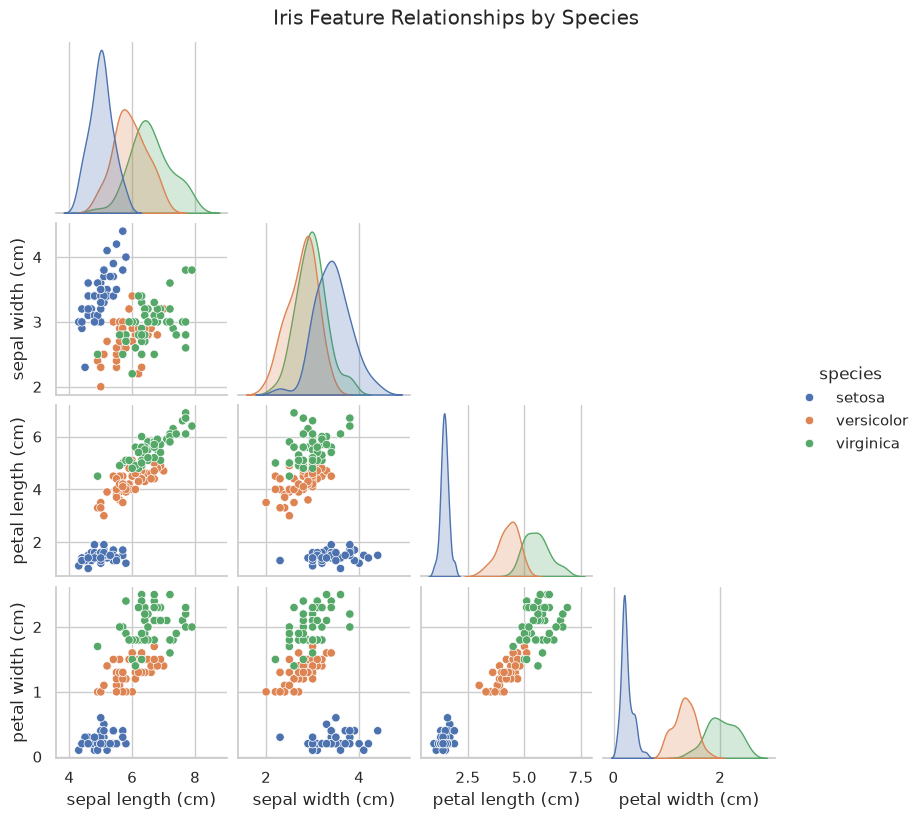

In [4]:
sns.pairplot(
    df.drop(columns=["target"]),
    hue="species",
    corner=True,
    height=2.0
)
plt.suptitle("Iris Feature Relationships by Species", y=1.02)
plt.show()

## 2. Train/Test Split & Baseline `XGBClassifier`

Before training, we split the data into **80% training** and **20% test** sets.
- `stratify=y` ensures each split keeps the exact same class proportions (important for small or imbalanced datasets).
- `random_state=42` makes our split reproducible across everyone's laptop.

In [5]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Train samples: 120, Test samples: 30


Now let's train a baseline `XGBClassifier`. Notice how closely its API matches `scikit-learn` (`fit`, `predict`, `predict_proba`):
- `n_estimators=50`: number of boosting rounds (trees added sequentially).
- `learning_rate=0.1` ($\eta$): shrinkage factor scaling each tree's contribution to prevent overfitting.
- `max_depth=3`: maximum depth of each tree (controls interaction complexity).
- `eval_metric="mlogloss"`: multi-class log loss used internally during training.

In [6]:
baseline_model = XGBClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="mlogloss",
    random_state=42
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)

# Inspect predictions vs. predicted class probabilities for the first 5 test samples
preview = pd.DataFrame(
    np.round(y_proba[:5], 3),
    columns=[f"prob_{name}" for name in iris.target_names]
)
preview["actual"] = [iris.target_names[i] for i in y_test.iloc[:5]]
preview["predicted"] = [iris.target_names[i] for i in y_pred[:5]]
preview

,prob_setosa,prob_versicolor,prob_virginica,actual,predicted
0,0.985,0.009,0.006,setosa,setosa
1,0.017,0.075,0.908,virginica,virginica
2,0.013,0.963,0.024,versicolor,versicolor
3,0.013,0.963,0.024,versicolor,versicolor
4,0.985,0.009,0.006,setosa,setosa


## 3. Model Evaluation

Accuracy gives us a single headline number, but in practice we also want:
1. **`classification_report`**: Precision, recall, and F1-score **per class**.
2. **`confusion_matrix`**: Exact counts of which classes get confused with each other.

In [7]:
acc = accuracy_score(y_test, y_pred)
print(f"Baseline Test Accuracy: {acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Baseline Test Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



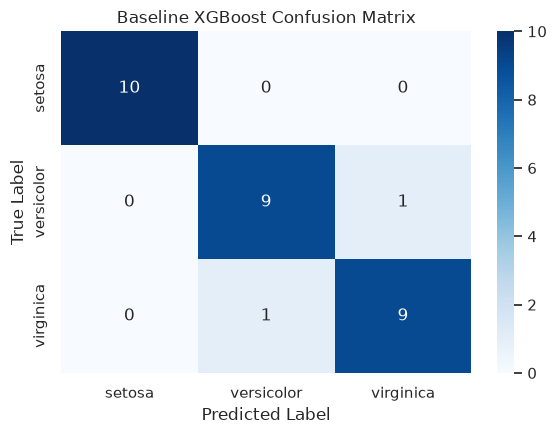

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Baseline XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

## 4. Opening the Black Box: Feature Importance & Tree Visualization

One big advantage of tree-based models over many neural networks is **interpretability**:
- `feature_importances_` tells us which features contributed the most to reducing loss across all boosted trees (default is `gain`-based in `XGBClassifier`).
- `plot_tree` lets us inspect an individual tree in the ensemble to see the exact split thresholds and leaf values (raw log-odds adjustments).

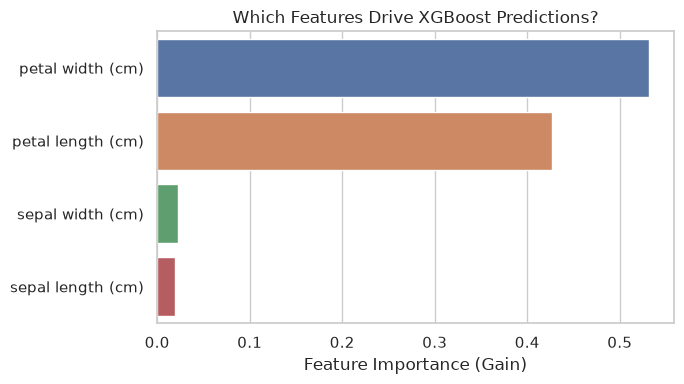

In [9]:
importances = baseline_model.feature_importances_
sorted_idx = np.argsort(importances)[::-1]

plt.figure(figsize=(7, 4))
sns.barplot(
    x=importances[sorted_idx],
    y=np.array(iris.feature_names)[sorted_idx],
    hue=np.array(iris.feature_names)[sorted_idx],
    legend=False
)
plt.xlabel("Feature Importance (Gain)")
plt.title("Which Features Drive XGBoost Predictions?")
plt.tight_layout()
plt.show()

Total Trees 50


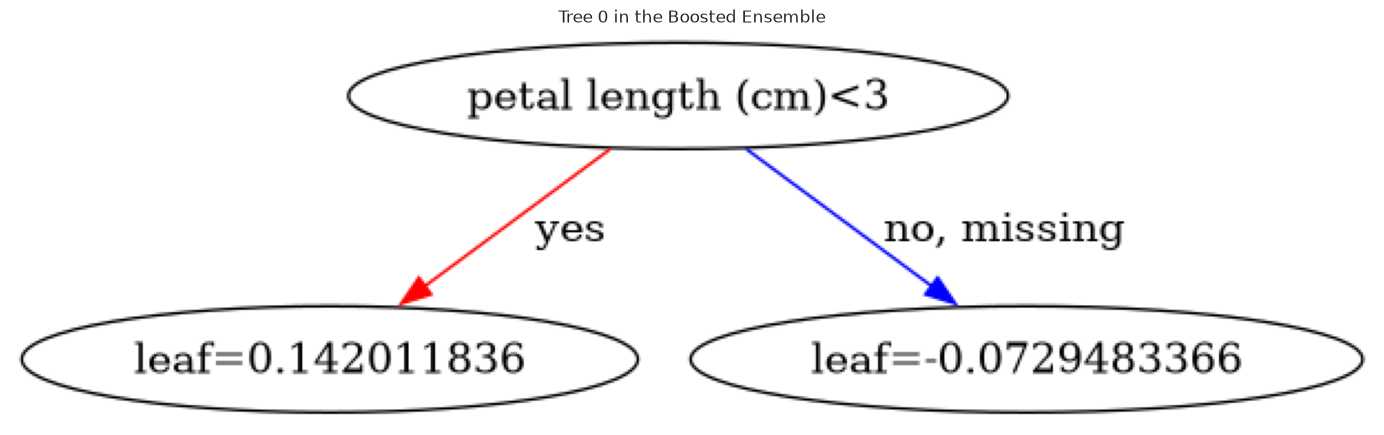

In [10]:
num_trees = baseline_model.get_booster().num_boosted_rounds()
print(f"Total Trees {num_trees}")

# Visualize the very first tree (index 0) in the ensemble
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(baseline_model, tree_idx=0, ax=ax)
plt.title("Tree 0 in the Boosted Ensemble")
plt.tight_layout()
plt.show()

## 5. Hyperparameter Tuning with `GridSearchCV`

In practice, default hyperparameters are only a starting point. Let's use 5-fold cross-validation (`GridSearchCV`) to search over three core XGBoost knobs:
- `n_estimators`: `[50, 100]` — more trees can fit finer patterns, but risk overfitting.
- `max_depth`: `[2, 3, 4]` — deeper trees capture higher-order feature interactions.
- `learning_rate`: `[0.05, 0.1, 0.2]` — smaller steps often generalize better when paired with more trees.

In [11]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1, 0.2],
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(eval_metric="mlogloss", random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best 5-Fold CV Accuracy: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best 5-Fold CV Accuracy: 0.9583


In [12]:
best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)

print(f"Tuned Test Accuracy: {accuracy_score(y_test, best_pred):.4f}\n")
print("Tuned Classification Report:")
print(classification_report(y_test, best_pred, target_names=iris.target_names))

Tuned Test Accuracy: 0.9333

Tuned Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

